# 03 · Evaluating honestly — threshold, ROC, mistakes

**Read first:** `01_theory/05_evaluation.md`

1. the threshold table: what each cut-off buys
2. the rule: the **highest** threshold whose recall ≥ 0.95, chosen on **validation**
3. the ROC curve and AUC — computed from scratch, checked against scikit-learn
4. the test split, opened once
5. look at the mistakes: which URLs fool the model, and why

In [1]:
import csv
from pathlib import Path

import joblib
import numpy as np
import matplotlib.pyplot as plt

# Run notebook 02 first: it saves the split and the trained models.
split = np.load("../data/_split.npz")
tr, va, te = split["tr"], split["va"], split["te"]
saved = joblib.load("../data/_models.joblib")
forest = saved["forest"]

urls, y = [], []
with open(Path("../data/phishing_urls.csv"), encoding="utf-8") as f:
    for row in csv.DictReader(f):
        urls.append(row["URL"]); y.append(1 if row["Label"] == "bad" else 0)
y = np.array(y)

from url_features import extract, FEATURE_NAMES       # the extractor built in notebook 01
X = np.array([extract(u) for u in urls])
p_va = forest.predict_proba(X[va])[:, 1]
p_te = forest.predict_proba(X[te])[:, 1]

## 1. What each threshold buys (validation split)

In [2]:
def metrics_at(p, y_true, t):
    pred = p >= t
    tp = np.sum(pred & (y_true == 1)); fn = np.sum(~pred & (y_true == 1)); fp = np.sum(pred & (y_true == 0))
    rec = tp / (tp + fn); prec = tp / (tp + fp) if tp + fp else 1.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return tp, fn, fp, rec, prec, f1

print("threshold   TP    FN    FP   recall  precision   F1")
for t in (0.7, 0.6, 0.5, 0.4, 0.3, 0.2):
    tp, fn, fp, rec, prec, f1 = metrics_at(p_va, y[va], t)
    print(f"  {t:.2f}    {tp:4d}  {fn:4d}  {fp:4d}   {rec:.3f}   {prec:.3f}    {f1:.3f}")

threshold   TP    FN    FP   recall  precision   F1
  0.70     632   221    40   0.741   0.940    0.829
  0.60     687   166    69   0.805   0.909    0.854
  0.50     734   119   106   0.860   0.874    0.867
  0.40     764    89   158   0.896   0.829    0.861
  0.30     788    65   220   0.924   0.782    0.847
  0.20     812    41   315   0.952   0.720    0.820


## 2. The rule: highest threshold with recall ≥ 0.95

Missing a phishing site costs more than a false alarm, so we buy recall with a little precision — but no more
than needed: the **highest** threshold that still reaches the target.

In [3]:
def choose_threshold(p, y_true, target_recall=0.95):
    for t in np.round(np.arange(0.99, 0.0, -0.01), 2):          # from high to low
        if metrics_at(p, y_true, t)[3] >= target_recall:
            return t
    return 0.0

t_star = choose_threshold(p_va, y[va])
print("chosen on validation:", t_star)

chosen on validation: 0.21


## 3. ROC and AUC, from scratch

Sweep the threshold from high to low; at each step record (false-alarm rate, recall). AUC = the area under that
curve, by the trapezoid rule. 0.5 = coin flip, 1.0 = perfect. It does not depend on any threshold.

random forest        AUC ours 0.9370   sklearn 0.9370
logistic (scratch)   AUC ours 0.8522   sklearn 0.8522


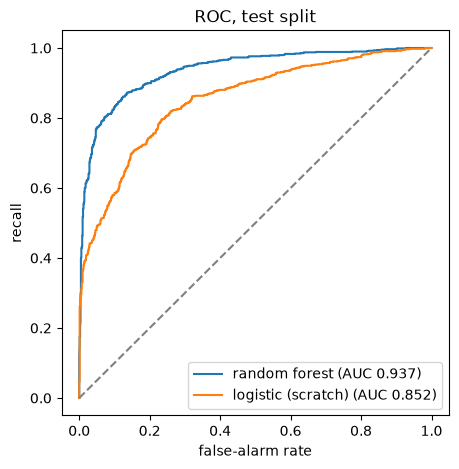

In [4]:
def roc_curve(p, y_true):
    order = np.argsort(-p, kind="stable")
    tps = np.cumsum(y_true[order] == 1); fps = np.cumsum(y_true[order] == 0)
    keep = np.r_[np.flatnonzero(np.diff(p[order])), len(p) - 1]        # one point per distinct score
    tpr = np.r_[0, tps[keep] / tps[-1]]; fpr = np.r_[0, fps[keep] / fps[-1]]
    return fpr, tpr

def auc(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))

from sklearn.metrics import roc_auc_score
Z = (X - saved["mean"]) / saved["std"]
p_log = 1 / (1 + np.exp(-(Z[te] @ saved["logistic_w"] + saved["logistic_b"])))

plt.figure(figsize=(5, 5))
for name, p in (("random forest", p_te), ("logistic (scratch)", p_log)):
    fpr, tpr = roc_curve(p, y[te])
    print(f"{name:20s} AUC ours {auc(fpr, tpr):.4f}   sklearn {roc_auc_score(y[te], p):.4f}")
    plt.plot(fpr, tpr, label=f"{name} (AUC {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "--", c="gray"); plt.xlabel("false-alarm rate"); plt.ylabel("recall")
plt.legend(); plt.title("ROC, test split"); plt.show()

## 4. The test split, once

In [5]:
for name, t in (("threshold 0.50", 0.5), (f"chosen {t_star:.2f}", t_star)):
    tp, fn, fp, rec, prec, f1 = metrics_at(p_te, y[te], t)
    print(f"{name:15s} recall {rec:.3f}  precision {prec:.3f}  F1 {f1:.3f}")

threshold 0.50  recall 0.857  precision 0.884  F1 0.870
chosen 0.21     recall 0.956  precision 0.748  F1 0.839


Compare with your success metrics: recall ≥ 0.95, precision ≥ 0.90, AUC ≥ 0.97. If one is missed on test,
**report it** — never go back and tune on test.

On **this** dataset the targets are not all reached: it is harder than the Kaggle file your project uses (its
legitimate URLs include many long, odd-looking real pages, and many phishing URLs sit on ordinary-looking
domains). Expect higher numbers on the Kaggle data — and if you have time, evaluate your final model on this
dataset too: a model that scores 97% on one dataset and 85% on another is a finding about generalisation.

## 5. The mistakes — the most instructive part

In [6]:
te_urls = np.array(urls)[te]
fp_idx = np.flatnonzero((p_te >= t_star) & (y[te] == 0))
fn_idx = np.flatnonzero((p_te < t_star) & (y[te] == 1))
print("FALSE ALARMS (legitimate, called phishing) - most confident first:")
for i in fp_idx[np.argsort(-p_te[fp_idx])][:8]:
    print(f"   {p_te[i]:.2f}  {te_urls[i][:100]}")
print("\nMISSED PHISHING - most confident first:")
for i in fn_idx[np.argsort(p_te[fn_idx])][:8]:
    print(f"   {p_te[i]:.2f}  {te_urls[i][:100]}")

FALSE ALARMS (legitimate, called phishing) - most confident first:
   0.99  http://www.kings-winchester.hants.sch.uk/
   0.99  http://animehometh2.blogspot.com
   0.98  http://thewebsiteofeverything.com/animals/mammals/Rodentia/Muridae/Mus/Mus-musculus.html
   0.96  https://accounts.google.com/ServiceLogin?service=blogger&hl=pt_BR&passive=true&continue=https://www.
   0.94  http://www.shellyfergusonphotography.com
   0.93  http://thejockstrapenthusiast.tumblr.com
   0.93  http://freecrackcorner4u.blogspot.com
   0.91  http://iwanarif.lecturer.pens.ac.id/2.%20network%20protocols.pdf

MISSED PHISHING - most confident first:
   0.01  https://fndtmc.com/
   0.01  http://lvk.hop.ru
   0.01  https://www.fortrader.com/
   0.01  https://news.acscinc.com/
   0.01  https://idgod.ph/
   0.02  http://doz.tode.cz/
   0.02  http://www.dalla.eu/
   0.02  https://frcamhpup.blogspot.com


Typical findings (theory §5.4): false alarms are long legitimate URLs full of parameters and digits; missed
phishing are short URLs on hijacked legitimate domains — the structure looks fine because the domain *is* fine.
That is the honest limit of URL-only detection: write it under "limitations" and use it to motivate page content
as future work.

## ✍️ Try it yourself

1. In the table of section 1, which threshold has the best F1? Why does our rule pick a different one?
2. Compute the ROC on the **training** split. Why is the AUC suspiciously close to 1?
3. Pick 5 of the missed phishing URLs and explain for each which feature would have caught it.

Then solve exercises 10–12 in `03_exercises/`.